# Figure 2C — Per-residue disorder traces on example CAID3 proteins

Disorder scores along four CAID3 Disorder-PDB proteins for the five best CAID3 predictors (by AUC; colours as in panel B) and metapredict V3. The bar under each trace is the Disorder-PDB reference: disordered (orange), ordered (green) and unscored (hatched grey), as in panels D/E and Figure S10. The proteins span a range of architectures: several IDRs (DP04127), balanced order/disorder (DP04242), mostly ordered (DP04068) and mostly disordered (DP03933).

**How it is made.** Traces are the per-residue scores in the CAID3 submission files (metapredict V3 from metapredict 3.1.0). The top five are ranked by AUC over the whole reference set.

**Output:** `figures/figure_2C.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid3_panels import N_TOP, load_predictions, load_reference, rank_predictors, trace_panel, trace_panel_height
from figtools import apply_style, require_metapredict_3_1, save_panel

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

TRACE_TARGETS = ['DP04127', 'DP04242', 'DP04068', 'DP03933']
TRACK_WIDTH_IN = 5.85  # leaves room for the tick and axis labels in a 6.4 in page width

metapredict 3.1.0+7.g7dcf52c.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 43b92cd)


In [2]:
# top five CAID3 predictors by AUC (same ranking as Figure 2A; see Figure S3A)
reference = load_reference()
predictions = load_predictions()
ranking = rank_predictors(reference, predictions)
series = [r.name for r in ranking[:N_TOP]] + ['Metapredict-v3']
print(series)

['PUNCH2', 'PUNCH2-Light', 'AlphaFold-rsa', 'SPOT-Disorder2', 'AlphaFold3-rsa', 'Metapredict-v3']


Wrote figures/figure_2C.pdf


PosixPath('figures/figure_2C.pdf')

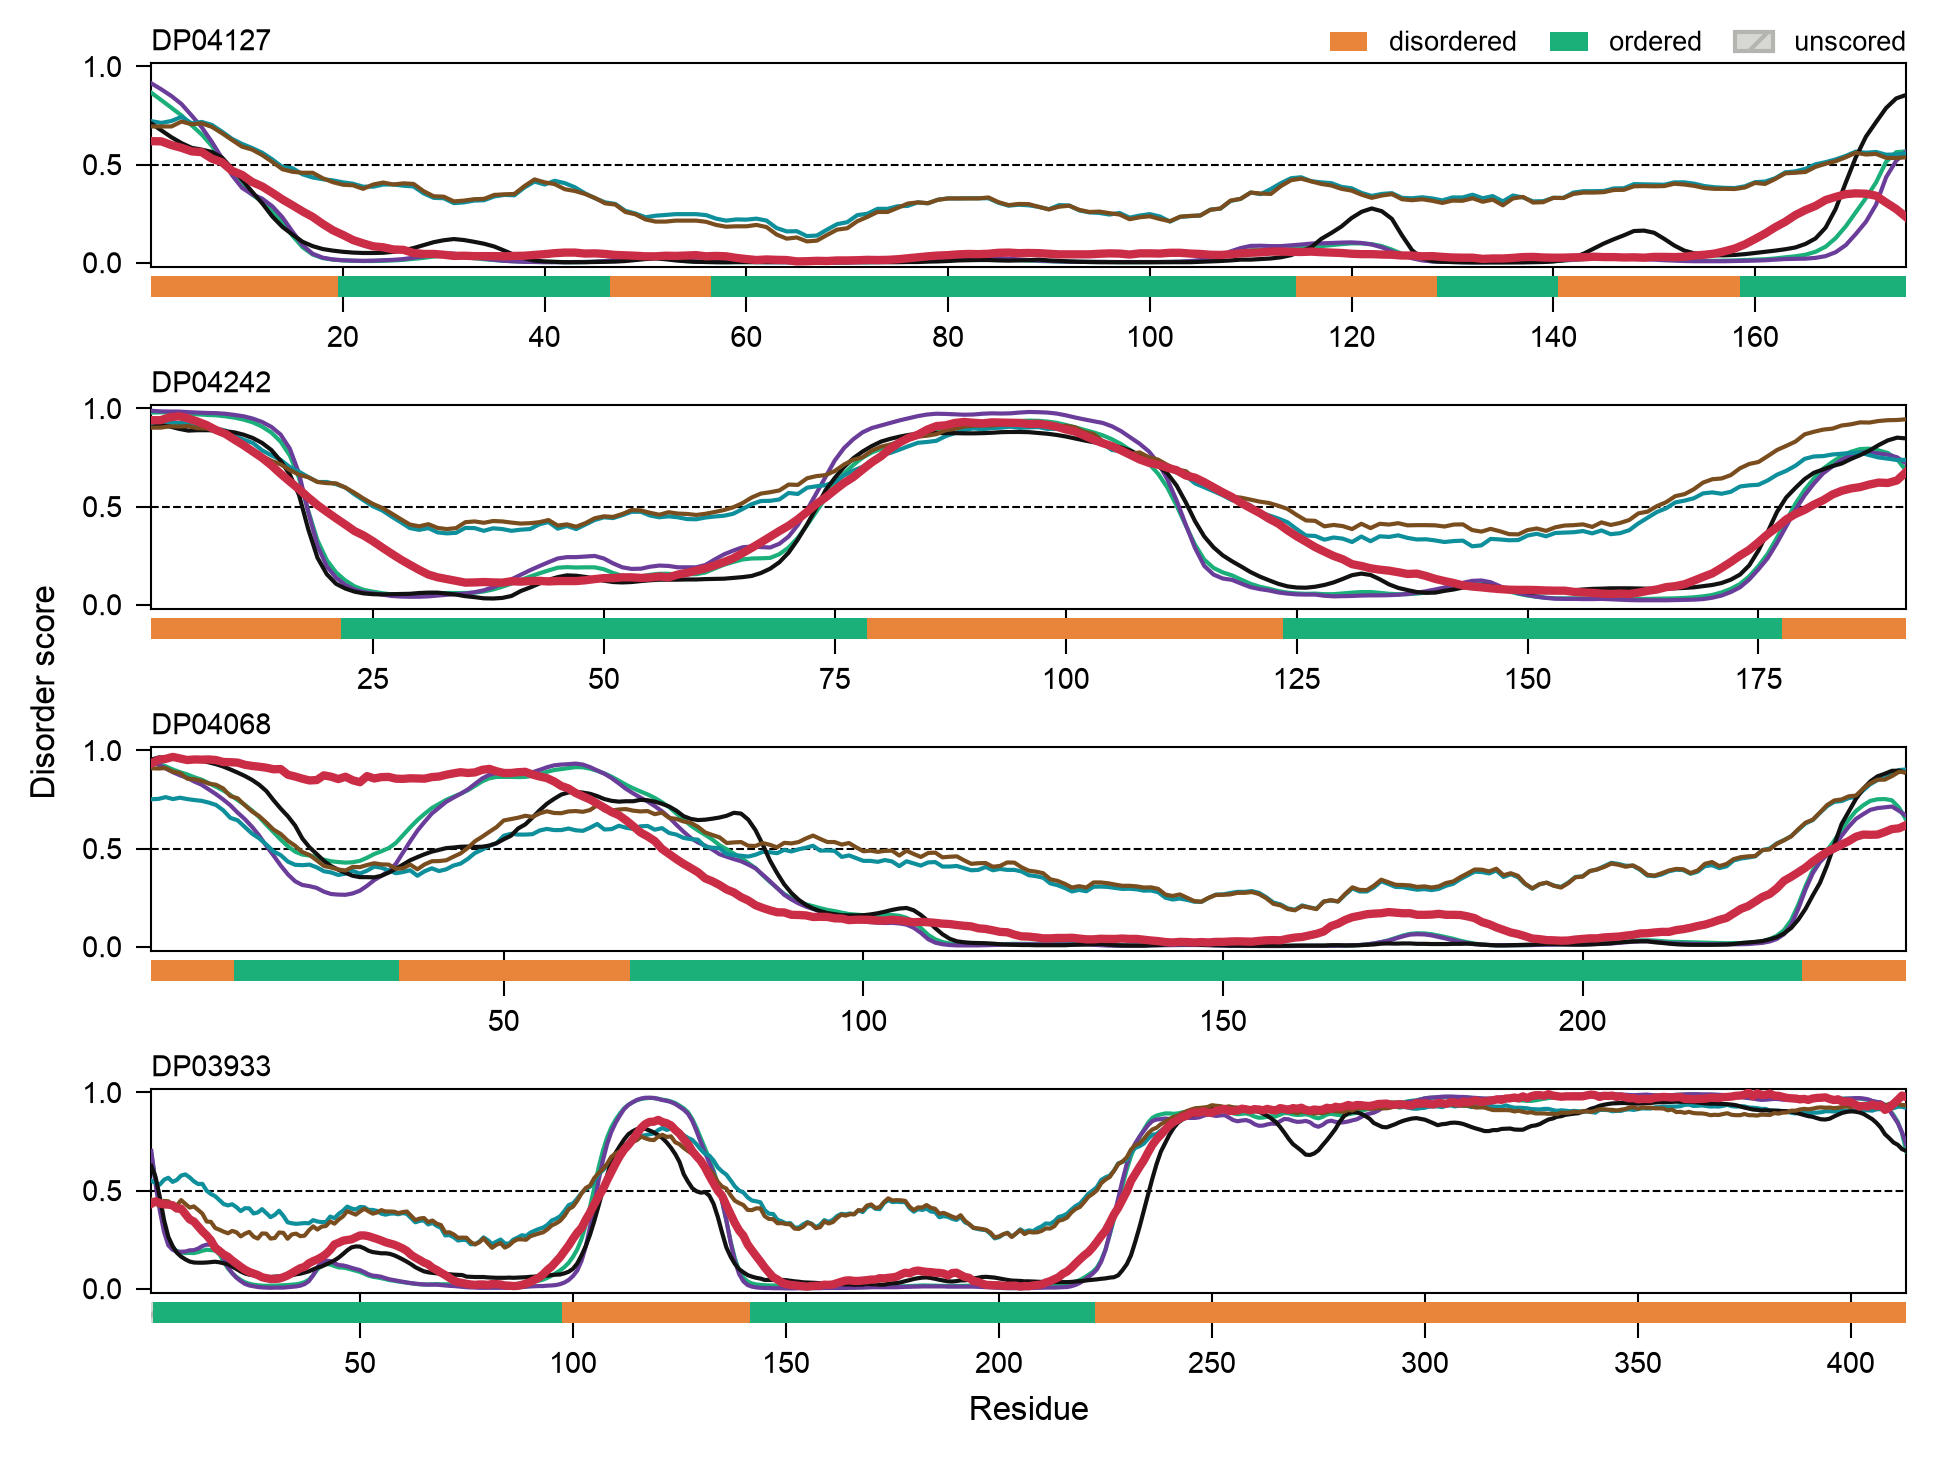

In [3]:
fig = plt.figure(figsize=(TRACK_WIDTH_IN, trace_panel_height(len(TRACE_TARGETS))), dpi=150)
# the predictor colours are keyed in panel B, so only the Disorder-PDB key is drawn here
trace_panel(fig, TRACE_TARGETS, series, reference, predictions, legend_predictors=False)
save_panel(fig, 'figure_2C')